For checking pipeline against selected low-pass ARTEMIS data.

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
from lunarmag import run_passes, analyse_pass

REPO = Path.cwd().resolve().parent
RAW, DERIVED = REPO / 'data' / 'raw', REPO / 'data' / 'derived'
DERIVED.mkdir(parents=True, exist_ok=True)

/Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load pass list from raw data file:

In [3]:
passes = pd.read_csv(RAW / 'thb_2012_2025_all_passes.csv')
passes['pass_id'] = passes['year'].astype(str) + '-' + passes['pass_number'].astype(str).str.zfill(2)
passes['t_peri'] = pd.to_datetime(passes['lowest_minute_utc']).dt.strftime('%Y-%m-%d/%H:%M:%S')

print(len(passes), 'passes; IDs unique:', passes['pass_id'].is_unique)
passes[['pass_id', 't_peri', 'lowest_altitude_km', 'latitude_deg', 'longitude_deg', 'sza_deg', 'phi_gse_deg']].head()

142 passes; IDs unique: True


,pass_id,t_peri,lowest_altitude_km,latitude_deg,longitude_deg,sza_deg,phi_gse_deg
0,2012-01,2012-01-19/20:25:00,38.5,9.05,274.32,47.76,-44.51
1,2012-02,2012-01-20/23:34:00,79.3,8.81,261.57,48.74,-29.79
2,2012-03,2012-02-02/13:30:00,67.0,10.09,89.02,30.14,116.05
3,2012-04,2012-02-15/03:18:00,49.2,10.49,280.95,16.26,-84.46
4,2012-05,2012-02-16/06:28:00,46.7,10.70,263.66,13.63,-69.89


List for overview of data:

In [4]:
print(passes.groupby('year').size().to_dict())
passes[['lowest_altitude_km', 'sza_deg', 'latitude_deg', 'duration_min']].describe().round(1)

{2012: 18, 2013: 15, 2014: 11, 2015: 8, 2016: 11, 2017: 9, 2018: 7, 2019: 9, 2020: 10, 2021: 6, 2022: 13, 2023: 9, 2024: 6, 2025: 10}


,lowest_altitude_km,sza_deg,latitude_deg,duration_min
count,142.0,142.0,142.0,142.0
mean,77.6,59.1,0.5,4.8
std,18.6,26.8,7.5,2.5
min,14.8,8.5,-10.9,1.0
25%,69.2,38.0,-7.1,3.0
50%,82.0,65.8,1.3,5.0
75%,90.7,84.4,7.9,6.0
max,99.7,89.9,10.9,12.0


Trial run on three passes first:

In [5]:
trial_ids = ['2013-12', '2013-13', '2013-14']
trial = passes[passes['pass_id'].isin(trial_ids)]

results, failures = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'])
failures

23-Nov-26 23:36:57: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 23:36:58: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 23:36:59: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:36:59: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:36:59: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:36:59: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:36:59: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:36:59: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 23:37:00: Creating spin model for probe b correction level 0
23-Nov-26 23:37:00: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:37:00: FGM correction variables not available
23-Nov-26 23:37:00: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 23:37:00: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 23:37:11: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 23:37:12: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 23:37:12: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 23:37:13: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 23:37:14: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:37:15: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:37:15: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:37:15: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:37:15: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:37:15: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 23:37:16: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 23:37:16: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 23:37:34: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 23:37:34: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 23:37:35: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:37:35: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:37:35: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:37:35: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:37:35: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:37:35: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 23:37:35: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 23:37:35: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed

""


Success! Check against data columns:

In [6]:
print(results.shape, passes.shape)
failures

(3, 35) (142, 21)


""


In [7]:
table = results.merge(passes, on='pass_id', suffixes=('', '_margot'))
table[['pass_id', 'min_alt_km', 'lowest_altitude_km', 'tail_angle_deg', 'phi_gse_deg', 'regime_geo', 'bg_ok', 'bg_sigma', 'post_status', 'n_used', 'peak_dB', 'peak_dBi']]

,pass_id,min_alt_km,lowest_altitude_km,tail_angle_deg,phi_gse_deg,regime_geo,bg_ok,bg_sigma,post_status,n_used,peak_dB,peak_dBi
0,2013-12,33.151552,33.5,175.613516,-0.66,solar_wind,False,0.911649,ok,248,2.988227,2.701883
1,2013-13,14.786443,14.8,161.731000,13.85,solar_wind,True,0.399926,disturbed,248,6.515042,5.717913
2,2013-14,86.387652,86.7,147.219551,28.47,solar_wind,True,0.149600,disturbed,276,3.356956,3.281770


In [8]:
stamp = pd.Timestamp.today().strftime('%Y-%m-%d')
results.to_csv(DERIVED / f'trial_results_{stamp}.csv', index=False)
failures.to_csv(DERIVED / f'trial_failures_{stamp}.csv', index=False)

All three passes asssociated with disturbed post_status and two had failed backgrounds. Check how tests failed:

In [9]:
table[['pass_id', 'bg_sigma', 'bg_r', 'bg_shift', 'post_window', 'post_sigma', 'post_shift', 'shadow_s']]

,pass_id,bg_sigma,bg_r,bg_shift,post_window,post_sigma,post_shift,shadow_s
0,2013-12,0.911649,0.754562,120.0,"(1386026190.0, 1386026370.0)",0.474022,-38.0,780.0
1,2013-13,0.399926,0.940293,12.0,"(1386116100.0, 1386116280.0)",2.050849,16.0,780.0
2,2013-14,0.149600,0.735600,-23.0,"(1386206040.0, 1386206220.0)",0.897016,45.0,600.0


2013-12: fails on noise and delay (bg_sigma and ng_shift, 120 at edge); also shift is negative, i.e. THC downstream from THB.

2013-13: passes!

2013-14: fails since we set r_min = 0.8 in background.py. Changed to 0.5 instead.

In [10]:
table = results.merge(passes, on='pass_id', suffixes=('', 'list'))
t0 = table['t_peri']
table['bg_start_s'] = [w[0] - tp for w, tp in zip(table['bg_window'], t0)]
table[['pass_id', 'bg_ok', 'bg_sigma', 'bg_r', 'bg_shift', 'bg_start_s','post_status', 'post_sigma', 'n_used', 'peak_dB', 'peak_dBi']]

,pass_id,bg_ok,bg_sigma,bg_r,bg_shift,bg_start_s,post_status,post_sigma,n_used,peak_dB,peak_dBi
0,2013-12,False,0.911649,0.754562,120.0,-840.0,ok,0.474022,248,2.988227,2.701883
1,2013-13,True,0.399926,0.940293,12.0,-480.0,disturbed,2.050849,248,6.515042,5.717913
2,2013-14,True,0.149600,0.735600,-23.0,-1170.0,disturbed,0.897016,276,3.356956,3.281770


Fitting window is problematic after applying criteria that THB must be above 0.5 lunar radii (870 km, c.f. Liuzzo et al. for ambient plasma), since THB spends most time below this cut. Check different windows to see which ones yield stable fits:

In [11]:
rows = []
for h in [0, 200, 500, 870]:
    res, fails = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'], bg_alt_min=h)
    res['bg_alt_min'] = h
    res['bg_start_s'] = [w[0] - tp for w, tp in zip(res['bg_window'], res['t_peri'])]
    rows.append(res)
    print(f'  bg_alt_min = {h}: {len(fails)} failed')

sweep = pd.concat(rows, ignore_index=True)
sweep.pivot_table(index='pass_id', columns='bg_alt_min', values=['bg_sigma', 'bg_shift', 'bg_start_s', 'bg_ok'], aggfunc='first')

23-Nov-26 23:37:46: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 23:37:46: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 23:37:47: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:37:47: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:37:47: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:37:47: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:37:48: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:37:48: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 23:37:48: Creating spin model for probe b correction level 0
23-Nov-26 23:37:48: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:37:48: FGM correction variables not available
23-Nov-26 23:37:48: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 23:37:48: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 23:38:00: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 23:38:00: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 23:38:01: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 23:38:01: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 23:38:03: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:38:03: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:38:03: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:38:03: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:38:03: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:38:04: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 23:38:04: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 23:38:05: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 23:38:22: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 23:38:23: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 23:38:24: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:38:24: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:38:24: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:38:24: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:38:24: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:38:24: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 23:38:24: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 23:38:24: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed  bg_alt_min = 0: 0 failed


... (15 outputs left out)

2/3 done, 0 failed

23-Nov-26 23:40:43: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 23:40:43: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 23:40:44: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:40:44: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:40:44: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:40:44: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:40:44: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:40:44: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 23:40:44: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 23:40:44: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed  bg_alt_min = 870: 0 failed


bg_ok                      bg_shift                       \
bg_alt_min    0      200    500    870      0      200    500    870   
pass_id                                                                
2013-12     False  False  False  False    120.0  120.0  113.0   22.0   
2013-13      True  False   True  False     12.0   16.0    0.0  -86.0   
2013-14      True   True   True  False    -23.0  -23.0  -23.0  120.0   

            bg_sigma                               bg_start_s                  \
bg_alt_min       0         200       500       870        0       200     500   
pass_id                                                                         
2013-12     0.911649  0.911649  0.605633  0.596116     -840.0  -840.0 -1140.0   
2013-13     0.399926  0.664617  0.465003  0.993630     -480.0  -810.0 -1140.0   
2013-14     0.149600  0.149600  0.149600  0.313044    -1170.0 -1170.0 -1170.0   

                    
bg_alt_min     870  
pass_id             
2013-12    -1650.0  
2013-13    -1800.0  
2013-14    -1560.0

Check for 2013-12 if true delay lies outside of 120s interval:

In [12]:
res, fails = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'], max_lag=300)
res[['pass_id', 'bg_ok', 'bg_sigma', 'bg_r', 'bg_shift']]

23-Nov-26 23:40:54: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 23:40:55: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 23:40:56: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:40:56: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:40:56: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:40:56: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:40:56: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:40:56: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 23:40:56: Creating spin model for probe b correction level 0
23-Nov-26 23:40:56: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:40:56: FGM correction variables not available
23-Nov-26 23:40:56: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 23:40:56: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 23:41:10: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 23:41:10: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 23:41:11: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 23:41:11: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 23:41:13: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:41:13: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:41:13: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:41:13: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:41:13: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:41:14: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 23:41:14: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 23:41:14: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 23:41:34: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 23:41:34: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 23:41:35: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:41:35: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:41:35: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:41:35: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:41:35: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:41:35: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 23:41:35: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 23:41:35: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed

,pass_id,bg_ok,bg_sigma,bg_r,bg_shift
0,2013-12,False,0.877199,0.802704,208.0
1,2013-13,True,0.399926,0.940293,12.0
2,2013-14,True,0.149600,0.735600,-23.0


Sigma still clearly not ok (>0.5), despite extended search times. Whatever. run a batch for bants:

In [13]:
stamp = pd.Timestamp.today().strftime('%Y-%m-%d')
out = DERIVED / f'batch_{stamp}_v2' # new folder
out.mkdir(exist_ok=True)

for year, grp in passes.groupby('year'):
    f_res = out / f'results_{year}.csv'
    if f_res.exists():
        print(year, 'already done'); continue
    res, fails = run_passes(grp['t_peri'].tolist(), ids=grp['pass_id'], no_update=True)
    res.to_csv(f_res, index=False)
    fails.to_csv(out / f'failures_{year}.csv', index=False)
    print(f'  {year}: {len(res)} ok, {len(fails)} failed')

import subprocess
commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
(out / 'run_info.txt').write_text(
    f'date: {stamp}\ncode commit: {commit}\npasses file: thb_2012_2025_all_passes.csv\n'
    f'defaults: sigma_max=0.5, r_min=0.5, max_lag=120, shadow_pad=120, bg_alt_min=0\n')

2012 already done
2013 already done
2014 already done
2015 already done
2016 already done
2017 already done
2018 already done
2019 already done
2020 already done
2021 already done
2022 already done
2023 already done
2024 already done
2025 already done


158

In [14]:
def read_all(pattern):
    """Read and combine the CSVs matching pattern, skipping empty ones."""
    files = [f for f in sorted(out.glob(pattern)) if f.stat().st_size > 1]
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()

results = read_all('results_*.csv')
failures = read_all('failures_*.csv')
print(len(results), 'ran,', len(failures), 'failed')
failures['error'].value_counts() if len(failures) else 'no failures'

0 ran, 142 failed


error
RuntimeError: thc: FGM data do not contain periapsis (stale or missing data)    4
ValueError: could not convert string to float: '2012-01-19 19:52:50.000000'     1
ValueError: could not convert string to float: '2012-01-20 23:01:50.000000'     1
ValueError: could not convert string to float: '2012-02-02 12:57:50.000000'     1
ValueError: could not convert string to float: '2012-02-15 02:45:50.000000'     1
                                                                               ..
ValueError: could not convert string to float: '2025-11-23 04:46:50.000000'     1
ValueError: could not convert string to float: '2025-11-24 05:31:50.000000'     1
ValueError: could not convert string to float: '2025-12-19 04:03:50.000000'     1
ValueError: could not convert string to float: '2025-12-20 04:48:50.000000'     1
ValueError: could not convert string to float: '2025-12-21 05:33:50.000000'     1
Name: count, Length: 139, dtype: int64

In [18]:
s = analyse_pass(passes.loc[passes['pass_id'] == '2013-13', 't_peri'].iloc[0], no_update=True)['summary']
print('n_strong' in s, s.get('n_strong'), s.get('peak_dBi_crust'), s.get('t_peak_dB'))

23-Nov-26 23:43:41: Local files found: ['themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf']
23-Nov-26 23:43:41: Local files found: ['themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf']
23-Nov-26 23:43:41: Local files found: ['themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf']
23-Nov-26 23:43:41: Local files found: ['themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf']
23-Nov-26 23:43:42: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:43:42: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:43:42: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:43:42: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:43:42: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:43:43: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 23:43:43: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 23:43:44: Creating spin model for p

True 52 5.717913417051809 -7.461111545562744


In [21]:
print(len(results), 'ran;', results['bg_ok'].mean().round(2), 'with good background')
results['post_status'].value_counts()

KeyError: 'bg_ok'

Stats:

In [ ]:
print(pd.crosstab(results['bg_ok'], results['post_status'], margins=True), '\n')

bad = results[~results['bg_ok']]
print('not ok:', len(bad))
print('  sigma > 0.5      :', (bad['bg_sigma'] > 0.5).sum())
print('  r < 0.5          :', (bad['bg_r'] < 0.5).sum())
print('  shift at the edge:', (bad['bg_shift'].abs() >= 120).sum())

post_status  disturbed  none  ok  All
bg_ok                                
False               49     4  14   67
True                29     9  14   52
All                 78    13  28  119 

not ok: 67
  sigma > 0.5      : 66
  r < 0.5          : 5
  shift at the edge: 2


Check distribution:

Text(0, 0.5, 'peak |ΔB| (nT)')

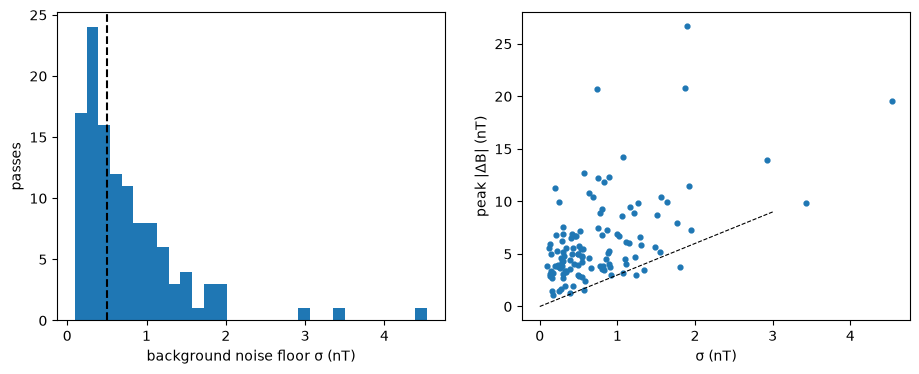

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(results['bg_sigma'], bins=30)
axs[0].axvline(0.5, color='k', ls='--')
axs[0].set_xlabel('background noise floor σ (nT)'); axs[0].set_ylabel('passes')

axs[1].scatter(results['bg_sigma'], results['peak_dB'], s=12)
axs[1].plot([0, 3], [0, 9], 'k--', lw=0.8)           # line peak = 3σ
axs[1].set_xlabel('σ (nT)'); axs[1].set_ylabel('peak |ΔB| (nT)')

In [ ]:
fit_valid = (results['bg_r'] >= 0.5) & (results['bg_shift'].abs() < 120)
sig = results['peak_dB'] / results['bg_sigma']

for smax in [0.5, 1.0, 2.0]:
    ok = fit_valid & (results['bg_sigma'] <= smax)
    print(f'sigma <= {smax}: {ok.sum():3d} valid,  {(ok & (sig >= 3)).sum():3d} at >=3σ,  {(ok & (sig >= 5)).sum():3d} at >=5σ')

cand = results[fit_valid & (results['bg_sigma'] <= 2.0) & (sig >= 5)].assign(signif=sig)
cand.sort_values('peak_dBi', ascending=False)[
    ['pass_id', 'min_alt_km', 'sza_peri', 'tail_angle_deg', 'bg_sigma', 'peak_svm', 'peak_dB', 'peak_dBi', 'signif']].head(10)

sigma <= 0.5:  52 valid,   52 at >=3σ,   50 at >=5σ
sigma <= 1.0:  84 valid,   83 at >=3σ,   77 at >=5σ
sigma <= 2.0: 110 valid,  105 at >=3σ,   92 at >=5σ


,pass_id,min_alt_km,sza_peri,tail_angle_deg,bg_sigma,peak_svm,peak_dB,peak_dBi,signif
61,2018-05,68.795998,95.086692,165.455976,1.898114,0.955732,26.646231,26.810216,14.038269
94,2022-08,99.418845,10.486184,109.180572,0.742672,0.413258,20.658782,20.761797,27.816849
99,2022-13,87.468795,76.188326,158.017434,1.872174,0.580054,20.760654,20.663783,11.089063
56,2017-09,95.796049,60.194620,149.114265,1.073366,0.477826,14.224993,14.124112,13.252691
11,2012-14,84.062297,72.545646,150.174792,0.568961,0.576154,12.737474,12.850148,22.387264
113,2025-03,73.651010,87.588660,172.728380,0.755752,0.337191,12.182981,12.180845,16.120343
58,2018-02,96.109413,62.409087,162.262166,0.894973,0.564494,12.313375,12.148841,13.758377
20,2013-07,26.302239,78.360912,156.148737,0.639250,3.250112,10.819343,12.024916,16.925064
16,2013-03,99.373487,44.599604,147.281516,0.831538,0.782022,11.868737,11.709183,14.273232
115,2025-07,84.757241,55.245740,132.367851,1.925193,0.368427,11.510725,11.431040,5.978999


In [ ]:
results[['n_strong', 'peak_dBi_crust', 't_peak_dB']].describe().round(1)

NameError: name 'results' is not defined

**BATCH CELL**

In [24]:
stamp = pd.Timestamp.today().strftime('%Y-%m-%d')
out = DERIVED / f'batch_{stamp}_v2'
out.mkdir(exist_ok=True)

for year, grp in passes.groupby('year'):
    f_res = out / f'results_{year}.csv'
    if f_res.exists():
        print(year, 'already done'); continue
    res, fails = run_passes(grp['t_peri'].tolist(), ids=grp['pass_id'], no_update=True)
    res.to_csv(f_res, index=False)
    fails.to_csv(out / f'failures_{year}.csv', index=False)
    print(f'  {year}: {len(res)} ok, {len(fails)} failed')

23-Nov-26 23:47:19: Local files found: ['themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120119_v01.cdf']
23-Nov-26 23:47:19: Local files found: ['themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120119_v01.cdf']
23-Nov-26 23:47:20: time_clip: thc_fgl_btotal has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgl_gse has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgl_gsm has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgl_dsl has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgl_ssl has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:47:20: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:47:20: File is current: themis_data/thb/l1/

1/18 done, 0 failed

23-Nov-26 23:47:30: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 23:47:30: Eclipse 1 of 2: start: 2012-01-19 18:16:22.786345  end: 2012-01-19 19:08:17.142554 status: in shadow, fully corrected
23-Nov-26 23:47:30: Eclipse 2 of 2: start: 2012-01-20 21:23:49.099152  end: 2012-01-20 22:13:13.537201 status: in shadow, fully corrected
23-Nov-26 23:47:30: Applying spin fit eclipse corrections to thb_fgs_gse
23-Nov-26 23:47:30: File is current: themis_data/thb/l1/state/2012/thb_l1_state_20120120.cdf
23-Nov-26 23:47:30: File is current: themis_data/thb/l1/state/2012/thb_l1_state_20120121.cdf
23-Nov-26 23:47:31: Creating spin model for probe b correction level 0
23-Nov-26 23:47:31: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:47:31: FGM correction variables not available
23-Nov-26 23:47:31: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 23:47:31: Creating spin model for probe b correction level 1
23-Nov-26 23:47:31: spin_correct

2/18 done, 0 failed

23-Nov-26 23:47:38: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 23:47:38: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 23:47:38: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 23:47:38: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 23:47:38: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 23:47:39: File is current: themis_data/thb/l1/state/2012/thb_l1_state_20120202.cdf
23-Nov-26 23:47:39: Creating spin model for probe b correction level 0
23-Nov-26 23:47:39: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:47:39: FGM correction variables not available
23-Nov-26 23:47:39: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 23:47:39: Creating spin model for probe b correction level 1
23-Nov-26 23:47:39: spin_correction variable not available, defaulting to 0.0
23-Nov-26 23:47:39: FGM correction variables not available
23-Nov-26 23:47:39: Skipping FGM

3/18 done, 0 failed

... (274 outputs left out)

24-Nov-26 00:10:54: time_clip: thc_fgl_btotal has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgl_gse has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgl_gsm has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgl_dsl has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgl_ssl has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 00:10:54: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 00:10:54: Eclipse correction status for probe ['b', 'c']:
24-Nov-26 00:10:54: Eclipse 1 of 2: start: 2025-12-19 04:42:45.111496  end: 2025-12-19 05:33:48.611722 status: in shadow, partially corrected (field waveforms corrected; particle data an

9/10 done, 2 failed

24-Nov-26 00:11:02: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 00:11:02: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 00:11:02: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 00:11:02: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 00:11:02: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 00:11:03: File is current: themis_data/thb/l1/state/2025/thb_l1_state_20251221.cdf
24-Nov-26 00:11:03: Creating spin model for probe b correction level 0
24-Nov-26 00:11:03: spin_correction variable not available, defaulting to 0.0
24-Nov-26 00:11:03: FGM correction variables not available
24-Nov-26 00:11:03: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
24-Nov-26 00:11:03: Creating spin model for probe b correction level 1
24-Nov-26 00:11:03: spin_correction variable not available, defaulting to 0.0
24-Nov-26 00:11:03: FGM correction variables not available
24-Nov-26 00:11:03: Skipping FGM

10/10 done, 2 failed  2025: 8 ok, 2 failed


Check batch downloaded correctly:

In [25]:
results = read_all('results_*.csv'); failures = read_all('failures_*.csv')
print(out)
print(len(results), 'ran,', len(failures), 'failed')
failures['error'].str.split(':').str[0].value_counts() if len(failures) else 'no failures'

/Users/yulun/artemis-lunar-plasma/data/derived/batch_2026-11-23_v2
119 ran, 23 failed


error
RuntimeError    23
Name: count, dtype: int64

In [26]:
print(results[['n_strong', 'peak_dBi_crust', 't_peak_dB']].describe().round(1), '\n')

fit_valid = (results['bg_r'] >= 0.5) & (results['bg_shift'].abs() < 120) & (results['bg_sigma'] <= 2.0)
sig = results['peak_dB'] / results['bg_sigma']
over_crust = results['n_strong'] > 0

print('fit valid:', fit_valid.sum())
print('  ... with a >=5σ detection:', (fit_valid & (sig >= 5)).sum())
print('  ... and flying over crust > 1 nT:', (fit_valid & (sig >= 5) & over_crust).sum())

cand = results[fit_valid & (sig >= 5) & over_crust].assign(signif=sig)
cand.sort_values('peak_dBi_crust', ascending=False)[['pass_id', 'min_alt_km', 'sza_peri', 'tail_angle_deg', 'bg_sigma', 'n_strong', 'peak_svm', 'peak_dBi_crust', 'peak_dB', 't_peak_dB', 'signif']].head(15)

       n_strong  peak_dBi_crust  t_peak_dB
count     119.0            15.0      119.0
mean        3.2             5.1       28.4
std        11.7             3.3      300.2
min         0.0             1.0     -611.8
25%         0.0             2.4     -163.4
50%         0.0             3.8       24.6
75%         0.0             6.9      230.5
max        77.0            12.0      657.2 

fit valid: 110
  ... with a >=5σ detection: 92
  ... and flying over crust > 1 nT: 14


,pass_id,min_alt_km,sza_peri,tail_angle_deg,bg_sigma,n_strong,peak_svm,peak_dBi_crust,peak_dB,t_peak_dB,signif
20,2013-07,26.302239,78.360912,156.148737,0.639250,45,3.250112,12.024916,10.819343,-22.383489,16.925064
19,2013-06,19.150370,78.302230,169.612382,0.252260,77,3.258167,10.100151,9.982085,126.685257,39.570691
0,2012-01,38.362840,46.896683,140.054715,1.559530,9,1.286413,8.338260,10.453365,257.900047,6.702896
7,2012-08,19.900562,23.774400,75.026334,1.508046,49,3.614672,7.417099,8.744244,-214.202194,5.798394
28,2014-04,44.012277,64.896775,161.658631,0.516183,28,2.209530,6.324228,7.210830,-130.401533,13.969518
44,2016-04,12.238772,91.144452,175.067091,0.303333,23,1.811248,6.173691,7.591887,-163.668344,25.028262
24,2013-13,14.786443,79.633482,161.731000,0.399926,52,4.683687,5.717913,6.515042,-7.461112,16.290618
17,2013-04,33.041121,44.615224,133.115109,0.436233,50,2.910727,3.847057,4.075709,51.195014,9.342965
4,2012-05,46.291906,14.931073,114.655091,1.267756,7,1.177555,3.593105,9.833711,159.454086,7.756789
30,2014-06,64.491273,33.562414,122.538575,0.321602,6,1.053821,3.510088,3.411098,45.232881,10.606569


**Quicklook function**

In [28]:
import matplotlib.pyplot as plt

def quicklook(pass_id, **kw):
    """Four-panel quick-look for one pass: ΔB vs SVM (east, north, up) and |ΔB| with altitude."""
    row = passes.loc[passes['pass_id'] == pass_id].iloc[0]
    r = analyse_pass(row['t_peri'], no_update=True, **kw)
    s = r['summary']
    t = r['t'] - s['t_peri'] #seconds from periapsis
    svm_mag = np.linalg.norm(r['svm_enr'], axis=1)
    over_crust = r['use'] & (svm_mag > 1.0)

    fig, axs = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
    for i, name in enumerate(['east', 'north', 'up']):
        axs[i].plot(t, r['dB_enr'][:, i], 'k', lw=0.8, label='ΔB')
        axs[i].plot(t, r['svm_enr'][:, i], 'C1', lw=1.2, label='SVM')
        axs[i].set_ylabel(f'{name} (nT)')
        axs[i].legend(loc='upper right', fontsize=8)

    dB_mag = np.linalg.norm(r['dB_enr'], axis=1)
    axs[3].plot(t, dB_mag, 'k', lw=0.8, label='|ΔB|')
    axs[3].plot(t, svm_mag, 'C1', lw=1.0, label='|SVM|')
    axs[3].axhline(3 * s['bg_sigma'], color='k', ls=':', label='3σ')
    axs[3].set_ylabel('|B| (nT)')
    axs[3].legend(loc='upper left', fontsize=8)
    ax2 = axs[3].twinx()
    ax2.plot(t, r['alt'], 'C0', lw=0.8)
    ax2.set_ylabel('altitude (km)', color='C0')

    for ax in axs:
        trans = ax.get_xaxis_transform()
        ax.fill_between(t, 0, 1, where=~r['use'], color='0.93', transform=trans)
        ax.fill_between(t, 0, 1, where=r['shadow'], color='0.80', transform=trans)
        ax.fill_between(t, 0, 1, where=over_crust, color='C2', alpha=0.15, transform=trans)
        if 't_peak_dB' in s:
            ax.axvline(s['t_peak_dB'], color='r', lw=0.8, ls='--')

    axs[-1].set_xlabel('seconds from periapsis')
    fig.suptitle(f"{pass_id}: σ = {s['bg_sigma']:.2f} nT, min alt = {s['min_alt_km']:.0f} km, " f"SZA = {s['sza_peri']:.0f}°, peak over crust = {s.get('peak_dBi_crust', np.nan):.1f} nT")
    return fig, r

plot v2:

In [29]:
figdir = REPO / 'figures' / 'quicklook'
figdir.mkdir(parents=True, exist_ok=True)

shortlist = cand.sort_values('peak_dBi_crust', ascending=False)
for pid in shortlist['pass_id']:
    fig, r = quicklook(pid)
    fig.savefig(figdir / f'{pid}.png', dpi=120, bbox_inches='tight')
    plt.close(fig)
    print(pid, 'saved')

shortlist.to_csv(out / 'shortlist.csv', index=False)

24-Nov-26 11:30:03: Local files found: ['themis_data/thb/l2/fgm/2013/thb_l2_fgm_20130211_v01.cdf']
24-Nov-26 11:30:03: Local files found: ['themis_data/thc/l2/fgm/2013/thc_l2_fgm_20130211_v01.cdf']
24-Nov-26 11:30:04: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 11:30:04: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 11:30:04: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 11:30:04: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 11:30:04: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 11:30:06: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20130211.cdf
24-Nov-26 11:30:06: Creating spin model for probe b correction level 0
24-Nov-26 11:30:06: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:30:06: FGM correction variables not available
24-Nov-26 11:30:06: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
24-Nov-26 11:30:06: Creating spin model fo

2013-07 saved


24-Nov-26 11:30:19: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20130210.cdf
24-Nov-26 11:30:19: Creating spin model for probe b correction level 0
24-Nov-26 11:30:19: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:30:19: FGM correction variables not available
24-Nov-26 11:30:19: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
24-Nov-26 11:30:19: Creating spin model for probe b correction level 1
24-Nov-26 11:30:19: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:30:19: Skipping FGM corrections, do_fgm_corr True, correction_level = 1
24-Nov-26 11:30:19: Creating spin model for probe b correction level 2
24-Nov-26 11:30:19: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:30:19: applying FGM corrections, do_fgm_corr = True, correction_level = 2
24-Nov-26 11:30:19: Spin axis corrections variable thb_spinras_correction not found, copying thb_spinras to thb_spinras_corrected
24-Nov-26 11:

2013-06 saved


24-Nov-26 11:30:26: time_clip: thc_fgl_btotal has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgl_gse has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgl_gsm has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgl_dsl has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgl_ssl has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 11:30:26: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 11:30:27: File is current: themis_data/thb/l1/state/2012/thb_l1_state_20120119.cdf
24-Nov-26 11:30:27: Creating spin model for probe b correction level 0
24-Nov-26 11:30:27: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11

2012-01 saved


... (18 outputs left out)

24-Nov-26 11:32:33: time_clip: thc_fgl_btotal has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgl_gse has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgl_gsm has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgl_dsl has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgl_ssl has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 11:32:33: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 11:32:34: File is current: themis_data/thb/l1/state/2020/thb_l1_state_20200314.cdf
24-Nov-26 11:32:34: Creating spin model for probe b correction level 0
24-Nov-26 11:32:34: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11

2020-06 saved


24-Nov-26 11:32:39: time_clip: thc_fgh_btotal has no data in requested range
24-Nov-26 11:32:39: time_clip: thc_fgh_gse has no data in requested range
24-Nov-26 11:32:39: time_clip: thc_fgh_gsm has no data in requested range
24-Nov-26 11:32:39: time_clip: thc_fgh_dsl has no data in requested range
24-Nov-26 11:32:39: time_clip: thc_fgh_ssl has no data in requested range
24-Nov-26 11:32:40: File is current: themis_data/thb/l1/state/2012/thb_l1_state_20120215.cdf
24-Nov-26 11:32:40: Creating spin model for probe b correction level 0
24-Nov-26 11:32:40: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:32:40: FGM correction variables not available
24-Nov-26 11:32:40: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
24-Nov-26 11:32:40: Creating spin model for probe b correction level 1
24-Nov-26 11:32:40: spin_correction variable not available, defaulting to 0.0
24-Nov-26 11:32:40: FGM correction variables not available
24-Nov-26 11:32:40: Skipping FGM

2012-04 saved


24-Nov-26 12:00:48: Local files found: ['themis_data/thb/l2/fgm/2013/thb_l2_fgm_20130210_v01.cdf']
24-Nov-26 12:00:48: Local files found: ['themis_data/thc/l2/fgm/2013/thc_l2_fgm_20130210_v01.cdf']
24-Nov-26 12:00:50: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20130210.cdf
24-Nov-26 12:00:50: Creating spin model for probe b correction level 0
24-Nov-26 12:00:50: spin_correction variable not available, defaulting to 0.0
24-Nov-26 12:00:50: FGM correction variables not available
24-Nov-26 12:00:50: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
24-Nov-26 12:00:50: Creating spin model for probe b correction level 1
24-Nov-26 12:00:50: spin_correction variable not available, defaulting to 0.0
24-Nov-26 12:00:50: Skipping FGM corrections, do_fgm_corr True, correction_level = 1
24-Nov-26 12:00:50: Creating spin model for probe b correction level 2
24-Nov-26 12:00:50: spin_correction variable not available, defaulting to 0.0
24-Nov-26 12:00:50: applying FGM

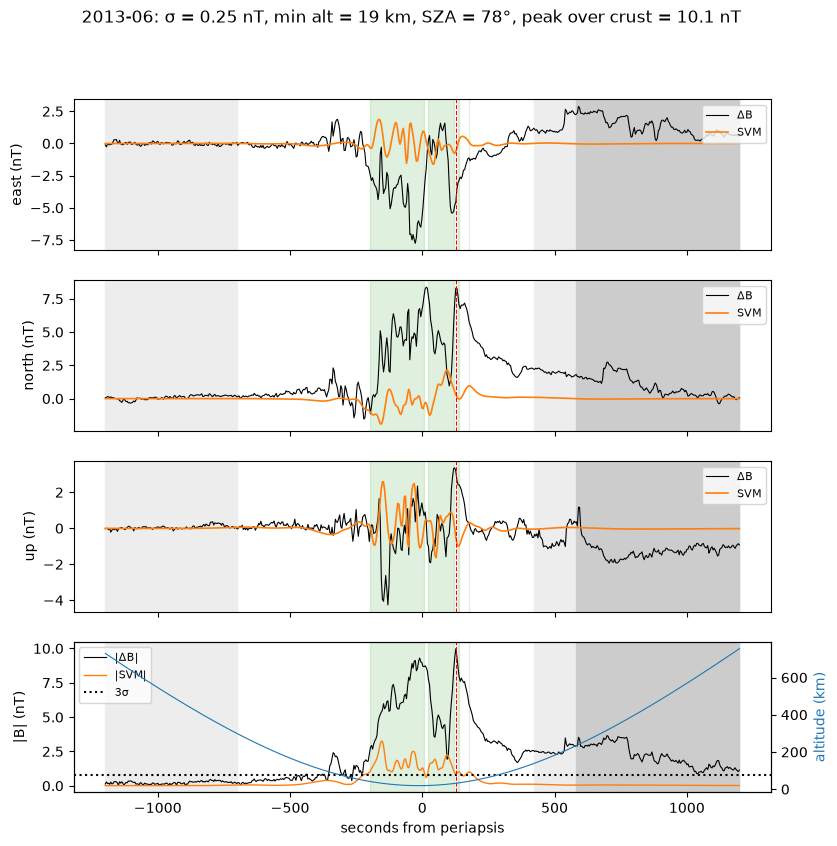

In [30]:
quicklook('2013-06');